# PlantSR · EDA and Center-Crop Preprocessing
AAI 521 Group 1 · Google Colab · CPU runtime

Run the cells from top to bottom. This notebook reads the official PlantSR training and test folders from your existing Google Drive connection. It audits the images, checks duplicates, creates train/validation/test manifests, and exports fixed 256 × 256 center crops for validation and testing. Training images remain full-size RGB images for random cropping during fine-tuning.

**Updated image handling:** an alpha channel is allowed when every alpha value is 255 (fully opaque). This makes `train/img271.jpg` eligible for normal processing even though its actual format is PNG/RGBA. Images with genuinely transparent pixels are still excluded. No source files are modified.

**New dataset version:** the default audit folder is `PlantSR_prepared_opaque_v2`, and the export goes to `PlantSR_prepared_opaque_v2_center256/prepared/`. This forces a fresh audit instead of reusing the earlier exclusion of `img271.jpg`. The previous output folders remain available. Adding an eligible image can change train/validation assignments; use the new manifests consistently across all four tasks.

Nominal counts before cleaning are 664 train, 166 validation, and 200 test. Read the final summary for the actual counts after cleaning. A center crop can contain mostly background if the plant is off-center, so inspect the galleries before sharing the finalized dataset.

## 1 · Install dependencies

Install the libraries used for image decoding, perceptual hashes, numerical summaries, and image previews. A Python 3 CPU runtime in Colab is sufficient. After installation, configure the existing MyDrive folders in the next cell.

In [3]:
# Install the image-processing, hashing, and plotting dependencies.
import subprocess
import sys

subprocess.run(
    [sys.executable, "-m", "pip", "install", "--quiet", "Pillow", "numpy", "ImageHash==4.3.2", "matplotlib"],
    check=True,
)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '--quiet', 'Pillow', 'numpy', 'ImageHash==4.3.2', 'matplotlib'], returncode=0)

## 2 · Mount Google Drive and configure project paths

This cell mounts Google Drive at `/content/drive` and sets `/content/drive/MyDrive/AAI521/Final_project` as the project folder. Run it at the start of each Colab session and authorize Drive access if prompted. The cell checks that the project folder and both source folders, `PlantSR_dataset/train` and `PlantSR_dataset/test`, exist.

The updated audit uses `PlantSR_prepared_opaque_v2` as its output folder so it can recheck `img271.jpg` without reusing the earlier audit that excluded it. The settings for this dataset version are seed `42`, a `20%` validation split from the official training set, a `256 × 256` crop size, and a perceptual hash distance threshold of `6` for flagging possible near duplicates.

The next three cells define the functions used to audit the images, check for duplicates, and export the prepared dataset.

In [4]:
# Configure the already-connected MyDrive folders and a fresh audit output directory.
from pathlib import Path
from types import SimpleNamespace
from google.colab import drive
drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/AAI521/Final_project")
if not PROJECT_DIR.is_dir():
    raise FileNotFoundError(
        f"Project folder is unavailable: {PROJECT_DIR}. "
        "Make sure Drive is already connected in Colab and this folder exists."
    )

DATASET_DIR = PROJECT_DIR / "PlantSR_dataset"
TRAIN_DIR = DATASET_DIR / "train"
TEST_DIR = DATASET_DIR / "test"
# Fresh audit: do not reuse the old transparency exclusion in PlantSR_prepared.
OUTPUT_DIR = PROJECT_DIR / "PlantSR_prepared_opaque_v2"

SEED = 42
VAL_FRACTION = 0.20
CROP_SIZE = 256
PHASH_THRESHOLD = 6

for name, path in {"Train": TRAIN_DIR, "Test": TEST_DIR}.items():
    if not path.is_dir():
        raise FileNotFoundError(f"{name} image directory was not found. Check this path: {path}")
    print(f"{name:>6}  {path}")
print(f"Output  {OUTPUT_DIR}")

Mounted at /content/drive
 Train  /content/drive/MyDrive/AAI521/Final_project/PlantSR_dataset/train
  Test  /content/drive/MyDrive/AAI521/Final_project/PlantSR_dataset/test
Output  /content/drive/MyDrive/AAI521/Final_project/PlantSR_prepared_opaque_v2


## 3.1 · Define image loading and shared helpers

These functions read/write CSV and JSON files, calculate hashes, load images, and prepare review previews. `load_rgb()` decodes the real image format, checks that any alpha channel is fully opaque, corrects EXIF orientation, and converts the result to RGB. A PNG named `.jpg` is therefore acceptable when its content is valid.

The preprocessing-policy marker is saved in the audit so later runs can detect records produced with the old transparency rule. Defining these helpers does not yet process the dataset; the next cell defines the audit itself.

In [5]:
# Define image loading, opaque-alpha validation, hashing, and report helpers.
from __future__ import annotations

import csv
import hashlib
import html
import json
import math
import platform
import random
from collections import Counter, defaultdict
from importlib.metadata import version
from pathlib import Path

try:
    import imagehash
    import numpy as np
    from PIL import Image, ImageDraw, ImageOps
except ImportError as exc:
    raise SystemExit("Install dependencies: python -m pip install Pillow numpy ImageHash") from exc

EXTENSIONS = {".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp", ".webp"}
SCHEMA_VERSION = 1
PREPROCESSING_POLICY = "allow_fully_opaque_alpha_v2"
REVIEW_FIELDS = ["id_a", "id_b", "phash_distance", "official_split_a",
                 "official_split_b", "decision"]


def fail(message):
    raise ValueError(message)


def sha_file(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def stable_key(*parts):
    return hashlib.sha256(json.dumps(parts, ensure_ascii=False).encode()).hexdigest()


def write_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")


def write_csv(path, rows, fields):
    with Path(path).open("w", encoding="utf-8", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=fields, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(rows)


def read_csv(path):
    with Path(path).open(encoding="utf-8-sig", newline="") as stream:
        return list(csv.DictReader(stream))


def environment():
    return {"python": platform.python_version(),
            **{name: version(name) for name in ("Pillow", "numpy", "ImageHash", "scipy")}}


def load_rgb(path):
    # load() really decodes the image; merely opening a header is not sufficient.
    with Image.open(path) as source:
        if getattr(source, "n_frames", 1) != 1:
            fail("unsupported_multiframe")
        if source.mode in {"I", "F"} or source.mode.startswith("I;16"):
            fail("unsupported_high_bit_depth")
        if "A" in source.getbands() or "transparency" in source.info:
            # Accept redundant alpha channels; reject actual transparent pixels.
            alpha = source.convert("RGBA").getchannel("A")
            if alpha.getextrema()[0] < 255:
                fail("unsupported_transparency")
        source.load()
        orientation = source.getexif().get(274, 1)
        metadata = {"original_mode": source.mode, "original_width": source.width,
                    "original_height": source.height, "exif_orientation": orientation}
        corrected = ImageOps.exif_transpose(source).convert("RGB")
        corrected.load()
        return corrected, metadata


def pixel_hash(image):
    h = hashlib.sha256(f"RGB:{image.width}:{image.height}:".encode())
    h.update(image.tobytes())
    return h.hexdigest()


def find_files(root):
    # Ignore macOS resource forks / hidden metadata directories.
    files = []
    ignored = []
    for path in sorted(root.rglob("*")):
        if not path.is_file():
            continue
        rel = path.relative_to(root)
        if any(part.startswith(".") or part == "__MACOSX" for part in rel.parts):
            continue
        (files if path.suffix.lower() in EXTENSIONS else ignored).append(path)
    return files, ignored


def quantiles(values):
    if not values:
        return None
    return dict(zip(("min", "q25", "median", "q75", "max"),
                    map(float, np.percentile(values, [0, 25, 50, 75, 100]))))


def contact_sheet(out, records, seed):
    chosen = sorted(records, key=lambda r: stable_key(seed, r["sample_id"]))[:36]
    if not chosen:
        return
    sheet = Image.new("RGB", (6 * 180, math.ceil(len(chosen) / 6) * 160), "white")
    draw = ImageDraw.Draw(sheet)
    for i, record in enumerate(chosen):
        with Image.open(out / "thumbnails" / (record["sample_id"] + ".jpg")) as thumb:
            thumb.thumbnail((176, 132))
            x, y = (i % 6) * 180, (i // 6) * 160
            sheet.paste(thumb, (x, y))
            draw.text((x + 2, y + 134), record["sample_id"], fill="black")
    sheet.save(out / "sample_contact_sheet.jpg", quality=90)


def review_html(out, pairs, records):
    by_id = {r["sample_id"]: r for r in records}
    body = ["<!doctype html><meta charset='utf-8'><title>PlantSR duplicate review</title>",
            "<style>body{font:16px sans-serif;margin:24px}article{display:flex;gap:20px;"
            "border-top:1px solid #ccc;padding:12px}figure{margin:0;width:320px}"
            "img{max-width:300px;height:220px;object-fit:contain}code{overflow-wrap:anywhere}</style>",
            "<h1>PlantSR near-duplicate review</h1><p>Fill decision in near_duplicate_review.csv: "
            "<b>same_source</b> or <b>distinct</b>. Similar leaves alone are not duplicates. "
            "Open originals for uncertain cases. Hash distance is not a probability.</p>"]
    for pair in pairs:
        body.append(f"<article><p>Distance: {pair['phash_distance']}</p>")
        for key in ("id_a", "id_b"):
            row = by_id[pair[key]]
            sid = row["sample_id"]
            body.append(f"<figure><img src='thumbnails/{sid}.jpg'><figcaption><b>{sid}</b><br>"
                        f"{html.escape(row['official_split'])}<br><code>"
                        f"{html.escape(row['relative_path'])}</code></figcaption></figure>")
        body.append("</article>")
    if not pairs:
        body.append("<p>No candidates at the selected threshold. This does not prove all images are independent.</p>")
    (out / "near_duplicates.html").write_text("\n".join(body), encoding="utf-8")

## 3.2 · Define the audit and duplicate screening

Using the image-loading helpers above, this function inventories each original, assigns a stable sample ID, checks crop-size eligibility, and records file/pixel hashes. It also identifies exact duplicates and possible near duplicates and saves EDA summaries and thumbnails.

This cell only defines `audit()`. Step 4 calls it after the export helpers in the next cell have been defined. The updated loader lets fully opaque RGBA images enter the same checks as ordinary RGB images.

In [6]:
# Define the source-image audit, eligibility checks, and duplicate screening.
def audit(args):
    roots = {"official_train": args.train_dir.resolve(), "official_test": args.test_dir.resolve()}
    out = args.out.resolve()
    a, b = roots.values()
    if not all(p.is_dir() for p in roots.values()):
        fail("Both TRAIN_DIR and TEST_DIR must exist.")
    if a == b or a in b.parents or b in a.parents:
        fail("Official train/test directories must be separate, non-nested folders.")
    if any(out == p or p in out.parents or out in p.parents for p in roots.values()):
        fail("OUTPUT_DIR must be outside, and must not contain, both source directories.")
    if out.exists() and any(out.iterdir()):
        fail("Audit output is not empty. Use a new OUTPUT_DIR directory to preserve previous decisions.")
    if args.crop_size < 1 or not 0 < args.val_fraction < 1 or not 0 <= args.phash_threshold <= 64:
        fail("Use positive crop size, 0 < val fraction < 1, and 0 <= pHash threshold <= 64.")
    discovered = {split: find_files(root) for split, root in roots.items()}
    if any(not item[0] for item in discovered.values()):
        fail("No images found in an official directory; check the extracted HR folder paths.")
    out.mkdir(parents=True, exist_ok=True)
    (out / "thumbnails").mkdir()
    records, ignored = [], []
    for split, root in roots.items():
        files, other_files = discovered[split]
        ignored.extend({"official_split": split, "path": str(p.relative_to(root))} for p in other_files)
        for index, path in enumerate(files):
            rel = path.relative_to(root).as_posix()
            sid = ("tr_" if split == "official_train" else "te_") + stable_key(split, rel)[:16]
            row = {"sample_id": sid, "official_split": split, "relative_path": rel,
                   "source_path": str(path), "file_bytes": path.stat().st_size,
                   "file_sha256": sha_file(path), "status": "ok", "reason": ""}
            try:
                rgb, metadata = load_rgb(path)
                row.update(metadata, width=rgb.width, height=rgb.height)
                if min(rgb.size) < args.crop_size:
                    row.update(status="excluded", reason="smaller_than_crop")
                else:
                    row.update(pixel_sha256=pixel_hash(rgb), phash=str(imagehash.phash(rgb)))
                    tiny = rgb.copy()
                    tiny.thumbnail((128, 128))
                    means = np.asarray(tiny, dtype=np.float32).mean(axis=(0, 1))
                    row.update(zip(("mean_R_approx", "mean_G_approx", "mean_B_approx"), map(float, means)))
                    rgb.thumbnail((300, 220))
                    rgb.save(out / "thumbnails" / f"{sid}.jpg", quality=85)
            except (OSError, ValueError, SyntaxError, Image.DecompressionBombError) as exc:
                row.update(status="excluded", reason=f"decode_or_format_error: {exc}")
            records.append(row)
            if (index + 1) % 100 == 0:
                print(f"Audited {split}: {index + 1}/{len(files)}", flush=True)
    if len({r["sample_id"] for r in records}) != len(records):
        fail("Unexpected sample ID collision.")
    valid = [r for r in records if r["status"] == "ok"]
    exact = defaultdict(list)
    for row in valid:
        exact[row["pixel_sha256"]].append(row)
    exact_rows = []
    for digest, group in sorted(exact.items()):
        for row in group if len(group) > 1 else []:
            exact_rows.append({"pixel_sha256": digest, "sample_id": row["sample_id"],
                               "official_split": row["official_split"], "relative_path": row["relative_path"]})
    pairs = []
    hashes = {r["sample_id"]: int(r["phash"], 16) for r in valid}
    for i, left in enumerate(valid):
        for right in valid[i + 1:]:
            if left["pixel_sha256"] == right["pixel_sha256"]:
                continue
            distance = (hashes[left["sample_id"]] ^ hashes[right["sample_id"]]).bit_count()
            if distance <= args.phash_threshold:
                pairs.append({"id_a": left["sample_id"], "id_b": right["sample_id"],
                              "phash_distance": distance, "official_split_a": left["official_split"],
                              "official_split_b": right["official_split"], "decision": ""})
    pairs.sort(key=lambda p: (p["phash_distance"], p["id_a"], p["id_b"]))
    config = {"schema_version": SCHEMA_VERSION, "preprocessing_policy": PREPROCESSING_POLICY,
              "seed": args.seed, "crop_size": args.crop_size,
              "val_fraction": args.val_fraction, "phash_threshold": args.phash_threshold,
              "roots": {k: str(v) for k, v in roots.items()}, "environment": environment()}
    payload = {"config": config, "records": records, "candidate_pairs": pairs}
    write_json(out / "audit.json", payload)
    fields = sorted(set().union(*(r.keys() for r in records)))
    write_csv(out / "inventory.csv", records, fields)
    write_csv(out / "exact_duplicates.csv", exact_rows,
              ["pixel_sha256", "sample_id", "official_split", "relative_path"])
    write_csv(out / "near_duplicate_review.csv", pairs, REVIEW_FIELDS)
    summaries = {}
    for split in roots:
        all_rows = [r for r in records if r["official_split"] == split]
        ok = [r for r in all_rows if r["status"] == "ok"]
        summaries[split] = {"discovered": len(all_rows), "eligible_before_deduplication": len(ok),
                           "excluded_reasons": dict(Counter(r["reason"] for r in all_rows if r["status"] != "ok")),
                           "original_modes": dict(Counter(r.get("original_mode", "unknown") for r in all_rows)),
                           "width_px": quantiles([r["width"] for r in ok]),
                           "height_px": quantiles([r["height"] for r in ok]),
                           "aspect_ratio": quantiles([r["width"] / r["height"] for r in ok]),
                           "file_bytes": quantiles([r["file_bytes"] for r in all_rows]),
                           "image_mean_RGB_approx": {c: quantiles([r[f"mean_{c}_approx"] for r in ok]) for c in "RGB"}}
    counts = {k: v["discovered"] for k, v in summaries.items()}
    warnings = []
    if counts != {"official_train": 830, "official_test": 200}:
        warnings.append("Source counts differ from expected 830/200. Verify official HR folders.")
    write_json(out / "EDA_summary.json", {"by_official_split": summaries, "warnings": warnings,
               "exact_duplicate_groups": sum(len(g) > 1 for g in exact.values()),
               "near_duplicate_candidates": len(pairs), "ignored_non_image_files": ignored,
               "notes": ["RGB summaries use thumbnails; these are not model normalization statistics.",
                         "No model selection should use test-image content or test metrics."]})
    review_html(out, pairs, valid)
    contact_sheet(out, valid, args.seed)
    print(f"Audit complete: {counts}; {len(pairs)} near-duplicate pairs to review.")
    for warning in warnings:
        print("WARNING:", warning)
    print("Continue with the EDA and duplicate review cells.")

## 3.3 · Define split assignment and center-crop export

These functions group exact or reviewed duplicates so related originals do not cross training, validation, and test sets. The builder verifies the audit policy and source hashes, chooses the validation groups deterministically, and writes images, crop coordinates, and manifests.

`center_crop_box()` selects a fixed 256 × 256 region from the image center without resizing. `random_train_crop()` is a helper for later training; export keeps full-size training images. After these definitions, Step 4 runs the audit on your files.

In [7]:
# Define duplicate grouping, deterministic splits, and fixed center-crop export.
class Groups:
    def __init__(self, ids):
        self.parent = {sid: sid for sid in ids}

    def find(self, sid):
        root = sid
        while self.parent[root] != root:
            root = self.parent[root]
        while self.parent[sid] != sid:
            previous = sid
            sid = self.parent[sid]
            self.parent[previous] = root
        return root

    def union(self, a, b):
        a, b = self.find(a), self.find(b)
        if a != b:
            self.parent[max(a, b)] = min(a, b)


def reviewed_groups(payload, review_path):
    valid = {r["sample_id"]: r for r in payload["records"] if r["status"] == "ok"}
    groups = Groups(valid)
    first = {}
    for sid, row in valid.items():
        digest = row["pixel_sha256"]
        if digest in first:
            groups.union(sid, first[digest])
        first[digest] = sid
    decisions = {}
    for line, row in enumerate(read_csv(review_path), 2):
        a, b = (row.get("id_a") or "").strip(), (row.get("id_b") or "").strip()
        decision = (row.get("decision") or "").strip().lower()
        if a not in valid or b not in valid or a == b:
            fail(f"Invalid sample IDs in review CSV line {line}.")
        if decision not in {"same_source", "distinct"}:
            fail(f"Unresolved review at line {line}: choose same_source or distinct.")
        key = tuple(sorted((a, b)))
        if key in decisions and decisions[key] != decision:
            fail(f"Conflicting decisions for {key}.")
        decisions[key] = decision
        if decision == "same_source":
            groups.union(a, b)
    required = {tuple(sorted((p["id_a"], p["id_b"]))) for p in payload["candidate_pairs"]}
    if required - decisions.keys():
        fail("Candidate rows are missing from review CSV. Restore and review all candidate pairs.")
    for (a, b), decision in decisions.items():
        if decision == "distinct" and groups.find(a) == groups.find(b):
            fail(f"Contradictory review: {a} and {b} are linked by same_source/exact matches but marked distinct.")
    return valid, groups


def choose_validation(group_rows, fraction, seed):
    """Choose whole groups nearest to target count, with seeded deterministic order."""
    n = sum(len(v) for v in group_rows.values())
    if len(group_rows) < 2:
        fail("Need at least two independent training-source groups for train/validation.")
    target = max(1, min(n - 1, math.floor(n * fraction + 0.5)))
    ordered = sorted(group_rows, key=lambda g: stable_key(seed, "split", g))
    # Subset-sum avoids arbitrary size drift when several originals share one group.
    reachable = {0: None}
    for gid in ordered:
        size = len(group_rows[gid])
        for count in list(reachable):
            if count + size not in reachable:
                reachable[count + size] = (count, gid)
    count = min((c for c in reachable if 0 < c < n), key=lambda c: (abs(c - target), c))
    chosen = set()
    while count:
        count, gid = reachable[count]
        chosen.add(gid)
    return chosen, target


def center_crop_box(width, height, size=256):
    """Return an in-bounds crop centered on the orientation-corrected image."""
    if min(width, height) < size:
        raise ValueError(f"Image {width} x {height} is smaller than crop size {size}.")
    x = (width - size) // 2
    y = (height - size) // 2
    return x, y, x + size, y + size


def random_train_crop(rgb, crop_size=256, rng=None):
    """Use inside training __getitem__ on the HR image BEFORE task degradation.

    Give each worker/epoch a correctly seeded, advancing RNG. Do not reset seed=42
    for every call. This helper is provided for convenience; build never calls it.
    """
    if min(rgb.size) < crop_size:
        fail("Training image is smaller than crop_size.")
    generator = rng if rng is not None else random
    x = generator.randint(0, rgb.width - crop_size)
    y = generator.randint(0, rgb.height - crop_size)
    return rgb.crop((x, y, x + crop_size, y + crop_size))


def build(args):
    out = args.out.resolve()
    audit_path, review_path = out / "audit.json", out / "near_duplicate_review.csv"
    payload = json.loads(audit_path.read_text(encoding="utf-8"))
    config = payload["config"]
    if config["schema_version"] != SCHEMA_VERSION:
        fail("Unsupported audit schema; use the script version that created the audit.")
    if config.get("preprocessing_policy") != PREPROCESSING_POLICY:
        fail("This audit uses an older image-loading policy. Rerun the audit in a new OUTPUT_DIR.")
    target_dir = out / "prepared"
    staging = out / "prepared_incomplete"
    if target_dir.exists() or staging.exists():
        fail("Prepared output already exists or a prior build was interrupted. See the notebook build cell.")
    valid, groups = reviewed_groups(payload, review_path)
    # Check both additions/removals and byte changes before trusting the frozen audit.
    for split, root in config["roots"].items():
        files, _ = find_files(Path(root))
        expected = {r["source_path"] for r in payload["records"] if r["official_split"] == split}
        if {str(p) for p in files} != expected:
            fail("Source image list changed after audit. Rerun audit into a new directory.")
    for row in payload["records"]:
        if sha_file(row["source_path"]) != row["file_sha256"]:
            fail(f"Source changed after audit: {row['source_path']}. Rerun audit.")
    excluded = [{"sample_id": r["sample_id"], "reason": r["reason"], "reference_id": ""}
                for r in payload["records"] if r["status"] != "ok"]
    components = defaultdict(list)
    for sid, row in valid.items():
        components[groups.find(sid)].append(row)
    train_groups, test_rows, test_related = {}, [], []
    for component in components.values():
        ids = sorted(r["sample_id"] for r in component)
        gid = "g_" + stable_key(*ids)[:16]
        for row in component:
            row["group_id"] = gid
        tests = [r for r in component if r["official_split"] == "official_test"]
        candidates = tests if tests else component
        # Keep test membership; drop any connected official-train samples.
        if tests:
            for row in component:
                if row["official_split"] == "official_train":
                    excluded.append({"sample_id": row["sample_id"], "reason": "same_source_as_official_test",
                                     "reference_id": sorted(r["sample_id"] for r in tests)[0]})
        kept, seen = [], {}
        for row in sorted(candidates, key=lambda r: r["sample_id"]):
            digest = row["pixel_sha256"]
            if digest in seen:
                excluded.append({"sample_id": row["sample_id"], "reason": "exact_pixel_duplicate",
                                 "reference_id": seen[digest]})
            else:
                seen[digest] = row["sample_id"]
                kept.append(row)
        if tests:
            test_rows.extend(kept)
            if len(kept) > 1:
                test_related.append({"group_id": gid, "sample_ids": [r["sample_id"] for r in kept]})
        else:
            train_groups[gid] = kept
    if not test_rows:
        fail("No eligible test images remain.")
    val_groups, val_target = choose_validation(train_groups, config["val_fraction"], config["seed"])
    assignments = {"train": [], "val": [], "test": test_rows}
    for gid, rows in train_groups.items():
        assignments["val" if gid in val_groups else "train"].extend(rows)
    seen_groups = {}
    for split, rows in assignments.items():
        for row in rows:
            gid = row["group_id"]
            if gid in seen_groups and seen_groups[gid] != split:
                fail("Internal error: a source group crossed splits.")
            seen_groups[gid] = split
    staging.mkdir()
    (staging / "manifests").mkdir()
    manifest_fields = ["sample_id", "group_id", "split", "official_split", "relative_path",
                       "width", "height", "file_sha256", "pixel_sha256", "hr_path", "eval_crop_path",
                       "crop_x", "crop_y", "crop_width", "crop_height"]
    for split, rows in assignments.items():
        (staging / "images" / split).mkdir(parents=True)
        if split != "train":
            (staging / "crops" / split).mkdir(parents=True)
        manifest = []
        for row in sorted(rows, key=lambda r: r["sample_id"]):
            rgb, _ = load_rgb(row["source_path"])
            if pixel_hash(rgb) != row["pixel_sha256"]:
                fail("Decoded pixels changed since audit. Preserve the environment and rerun audit.")
            sid = row["sample_id"]
            hr_path = f"images/{split}/{sid}.png"
            # Strip EXIF/other metadata: pixels are already corrected and are the target.
            rgb.info.clear()
            rgb.save(staging / hr_path)
            item = {**row, "split": split, "hr_path": hr_path, "eval_crop_path": "",
                    "crop_x": "", "crop_y": "", "crop_width": "", "crop_height": ""}
            if split != "train":
                size = config["crop_size"]
                box = center_crop_box(rgb.width, rgb.height, size)
                crop_path = f"crops/{split}/{sid}.png"
                rgb.crop(box).save(staging / crop_path)
                item.update(eval_crop_path=crop_path, crop_x=box[0], crop_y=box[1],
                            crop_width=size, crop_height=size)
            manifest.append(item)
        write_csv(staging / "manifests" / f"{split}.csv", manifest, manifest_fields)
    write_csv(staging / "manifests" / "excluded.csv", excluded, ["sample_id", "reason", "reference_id"])
    counts = {split: len(rows) for split, rows in assignments.items()}
    summary = {"config": config, "build_environment": environment(), "final_counts": counts,
               "eval_crop_policy": "center",
               "target_validation_count_after_cleaning": val_target,
               "excluded_total": len(excluded), "exclusion_counts": dict(Counter(r["reason"] for r in excluded)),
               "official_test_excluded": [r["sample_id"] for r in excluded if r["sample_id"].startswith("te_")],
               "related_groups_within_test": test_related, "audit_sha256": sha_file(audit_path),
               "review_sha256": sha_file(review_path),
               "cross_split_detected_or_reviewed_group_overlap": False,
               "notes": ["Near-duplicate screening cannot prove no undetected relationships exist.",
                         "Every crop/degradation must inherit its original sample_id and split.",
                         "Test exclusion changes the official benchmark; disclose counts and exclusions.",
                         "Evaluate fixed crops for crop-based results, not full-image benchmark claims."]}
    if sum(counts.values()) + len(excluded) != len(payload["records"]):
        fail("Internal error: counts do not reconcile.")
    write_json(staging / "summary.json", summary)
    # A final prepared/ directory only appears after a successful complete build.
    staging.rename(target_dir)
    print("Build complete:", json.dumps(counts), f"; excluded={len(excluded)}")
    print(f"Share these manifests with all teammates: {target_dir / 'manifests'}")
    print("Train: full RGB images, random crops during training. Val/test: fixed HR crops.")
    if summary["official_test_excluded"] or test_related:
        print("WARNING: See summary.json for official-test exclusions / related test groups.")

## 4 · Run the audit and inspect the dataset summary

Run the audit on the original training and test folders using the updated image loader. On the first run, the cell saves `audit.json`, `inventory.csv`, an exploratory data analysis (EDA) summary, duplicate reports, and thumbnails in the new output folder. On subsequent runs, it reuses the saved audit if the recorded settings and preprocessing policy match the current notebook.

The summary reports how many images are eligible before duplicate removal. The previous audit excluded `img271.jpg` because it has an alpha channel. All its alpha values are `255`, meaning every pixel is fully opaque, so the updated loader should accept it and convert it to RGB. The notebook checks whether the image appears in the final manifests after export.

Review any near-duplicate candidates before finalizing the dataset splits. A fresh audit can identify new pairs or change their numbering, so record your decisions using the pair numbers shown in the current preview.

Audited official_train: 100/830
Audited official_train: 200/830
Audited official_train: 300/830
Audited official_train: 400/830
Audited official_train: 500/830
Audited official_train: 600/830
Audited official_train: 700/830
Audited official_train: 800/830
Audited official_test: 100/200
Audited official_test: 200/200
Audit complete: {'official_train': 830, 'official_test': 200}; 0 near-duplicate pairs to review.
Continue with the EDA and duplicate review cells.


| Official folder | Images found | Images eligible for cropping | Median width × height |
|---|---:|---:|---:|
| official_train | 830 | 830 | 1600 × 1197 |
| official_test | 200 | 200 | 1600 × 1187 |

Exact duplicate groups 1
Possible near-duplicate pairs 0


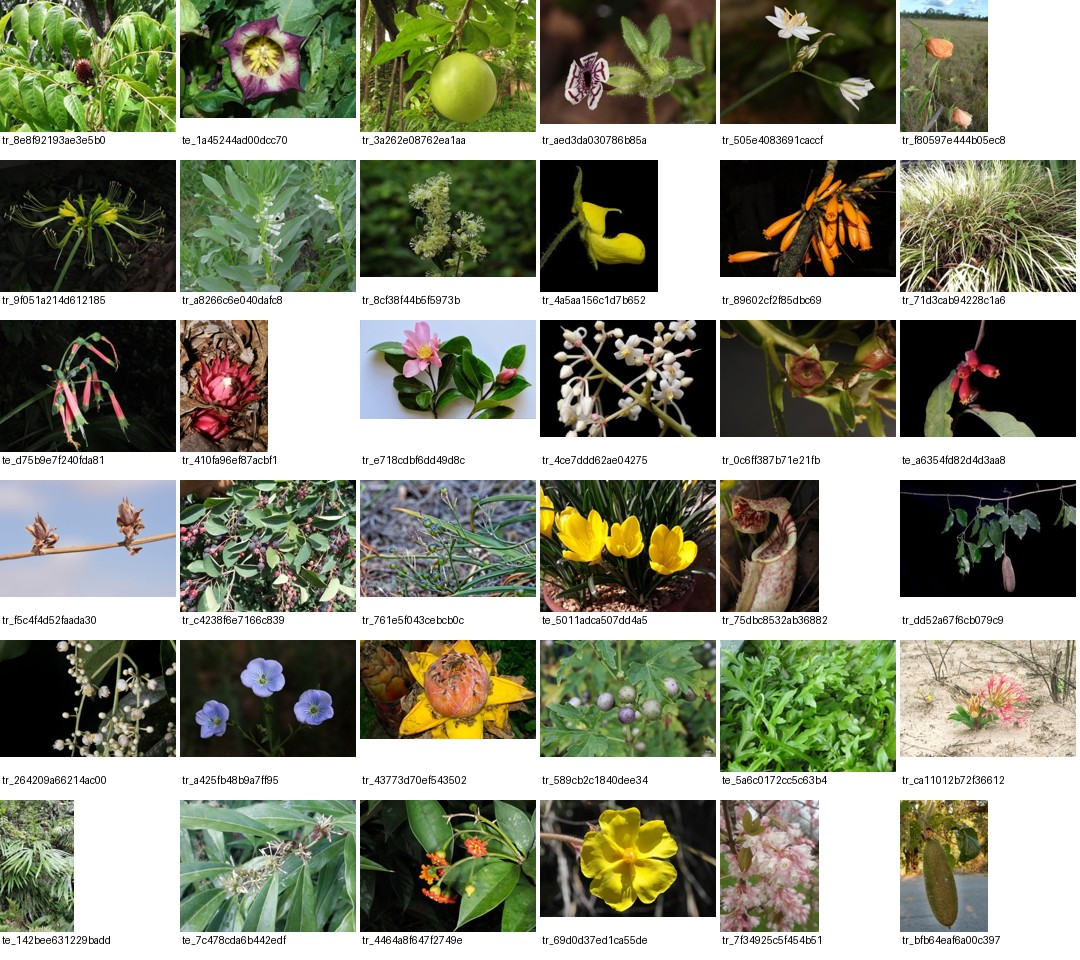

In [8]:
# Run or validate the updated audit, then show the dataset summary.
from IPython.display import Image as DisplayImage, Markdown, display

audit_path = OUTPUT_DIR / "audit.json"
review_path = OUTPUT_DIR / "near_duplicate_review.csv"
eda_path = OUTPUT_DIR / "EDA_summary.json"

if audit_path.exists():
    for required_path in (review_path, eda_path):
        if not required_path.is_file():
            raise RuntimeError(
                f"The audit did not finish writing {required_path.name}. Set a new OUTPUT_DIR and rerun the audit."
            )
    print(f"Found an existing audit at {audit_path}")
else:
    audit(SimpleNamespace(
        train_dir=TRAIN_DIR,
        test_dir=TEST_DIR,
        out=OUTPUT_DIR,
        seed=SEED,
        crop_size=CROP_SIZE,
        val_fraction=VAL_FRACTION,
        phash_threshold=PHASH_THRESHOLD,
    ))

audit_data = json.loads(audit_path.read_text(encoding="utf-8"))
current_settings = {
    "schema_version": SCHEMA_VERSION,
    "preprocessing_policy": PREPROCESSING_POLICY,
    "seed": SEED,
    "crop_size": CROP_SIZE,
    "val_fraction": VAL_FRACTION,
    "phash_threshold": PHASH_THRESHOLD,
    "roots": {
        "official_train": str(TRAIN_DIR.resolve()),
        "official_test": str(TEST_DIR.resolve()),
    },
}
different_settings = [
    name for name, value in current_settings.items()
    if audit_data["config"].get(name) != value
]
if different_settings:
    raise ValueError(f"The existing audit differs from the current settings in {different_settings}. Use a new OUTPUT_DIR.")

eda = json.loads(eda_path.read_text(encoding="utf-8"))
table = [
    "| Official folder | Images found | Images eligible for cropping | Median width × height |",
    "|---|---:|---:|---:|",
]
for split, stats in eda["by_official_split"].items():
    width, height = stats["width_px"], stats["height_px"]
    median_size = f"{width['median']:.0f} × {height['median']:.0f}" if width and height else "—"
    table.append(
        f"| {split} | {stats['discovered']} | "
        f"{stats['eligible_before_deduplication']} | {median_size} |"
    )
display(Markdown("\n".join(table)))
print("Exact duplicate groups", eda["exact_duplicate_groups"])
print("Possible near-duplicate pairs", eda["near_duplicate_candidates"])
for warning in eda["warnings"]:
    print(warning)
contact_path = OUTPUT_DIR / "sample_contact_sheet.jpg"
if contact_path.is_file():
    display(DisplayImage(filename=str(contact_path)))

## 5.1 · Preview possible near duplicates

The audit identifies candidate pairs using perceptual-hash similarity. Compare each pair visually; similar leaves alone do not mean two photos share an original. Exact pixel duplicates are handled automatically during export.

This cell displays up to eight candidate pairs. Change `START_PAIR` to inspect later pairs, then enter decisions in the next cell. If no candidates are found, continue through the decision cell with the dictionary empty.

In [9]:
# Preview possible near-duplicate pairs before entering review decisions.
START_PAIR = 1
PAIRS_PER_PAGE = 8

candidates = audit_data["candidate_pairs"]
record_by_id = {record["sample_id"]: record for record in audit_data["records"]}

def review_pair_key(row):
    return tuple(sorted((row["id_a"], row["id_b"])))

review_rows = read_csv(review_path)
saved_decisions = {
    review_pair_key(row): (row.get("decision") or "").strip().lower()
    for row in review_rows
}
if not candidates:
    print("No possible near duplicates were found. Continue to the next cell.")
else:
    if not 1 <= START_PAIR <= len(candidates) or PAIRS_PER_PAGE < 1:
        raise ValueError("Set START_PAIR to a valid pair number and PAIRS_PER_PAGE to a positive integer.")
    stop = min(len(candidates), START_PAIR - 1 + PAIRS_PER_PAGE)
    print(f"Showing pairs {START_PAIR}–{stop} of {len(candidates)}")
    for number in range(START_PAIR, stop + 1):
        pair = candidates[number - 1]
        decision = saved_decisions.get(review_pair_key(pair)) or "Pending review"
        print(f"\nPair {number} | pHash distance {pair['phash_distance']} | {decision}")
        panel = Image.new("RGB", (620, 230), "white")
        for offset, field in enumerate(("id_a", "id_b")):
            row = record_by_id[pair[field]]
            side = "Left" if offset == 0 else "Right"
            print(f"{side}  {row['official_split']}/{row['relative_path']}  ({row['sample_id']})")
            thumb_path = OUTPUT_DIR / "thumbnails" / f"{row['sample_id']}.jpg"
            with Image.open(thumb_path) as thumbnail:
                panel.paste(thumbnail, (offset * 310, 0))
        display(panel)

No possible near duplicates were found. Continue to the next cell.


## 5.2 · Record duplicate-review decisions

Use the pair numbers from the current preview and enter `"same_source"` or `"distinct"` in `REVIEW_DECISIONS`. The cell writes changed decisions to the review CSV and reports unresolved pairs. Leave the dictionary empty if no candidates exist or all decisions are already saved.

The export will stop if any pair remains unresolved. Once the pending count is zero, continue to create the split manifests and center crops.

In [10]:
# Enter your decisions using the pair numbers shown above.
REVIEW_DECISIONS = {
    # 1: "same_source",
    # 2: "distinct",
}

candidates = audit_data["candidate_pairs"]
review_rows = read_csv(review_path)
if REVIEW_DECISIONS:
    rows_by_pair = {review_pair_key(row): row for row in review_rows}
    changed_decisions = 0
    for number, decision in REVIEW_DECISIONS.items():
        if type(number) is not int or not 1 <= number <= len(candidates):
            raise ValueError(f"Invalid pair number {number!r}")
        if decision not in {"same_source", "distinct"}:
            raise ValueError(f"Use same_source or distinct for pair {number}.")
        pair_key = review_pair_key(candidates[number - 1])
        if pair_key not in rows_by_pair:
            raise ValueError(f"Pair {number} is missing from the review CSV.")
        row = rows_by_pair[pair_key]
        if (row.get("decision") or "").strip().lower() != decision:
            row["decision"] = decision
            changed_decisions += 1
    if changed_decisions:
        if (OUTPUT_DIR / "prepared").exists():
            raise RuntimeError("The splits already exist. To change a review decision, rerun with a new OUTPUT_DIR.")
        temporary_review = review_path.with_suffix(".tmp")
        write_csv(temporary_review, review_rows, REVIEW_FIELDS)
        temporary_review.replace(review_path)
        print(f"Saved {changed_decisions} review decisions to {review_path.name}")

decision_by_pair = {
    review_pair_key(row): (row.get("decision") or "").strip().lower()
    for row in review_rows
}
remaining = [
    i for i, pair in enumerate(candidates, start=1)
    if decision_by_pair.get(review_pair_key(pair)) not in {"same_source", "distinct"}
]
print(f"Pairs pending review: {len(remaining)} of {len(candidates)}")
if remaining:
    print(f"Pending pair numbers (first 20): {remaining[:20]}")

Pairs pending review: 0 of 0


## 6.1 · Export the prepared dataset and fixed center crops

After all candidate pairs have decisions, build the dataset from the new audit. The export copies the audit and current review CSV, checks source-file hashes, removes exact duplicates, and assigns whole source groups to train or validation. Official test images remain reserved for testing, subject to the documented cleaning rules.

Full-size RGB images are saved in `prepared/images/{split}/`. Each validation/test image also produces one 256 × 256 center crop in `prepared/crops/val/` or `prepared/crops/test/`; the CSV manifests record its coordinates. For odd margins, the crop is one pixel closer to the top or left. Training crops are generated later, inside the training workflow.

The new export is `PlantSR_prepared_opaque_v2_center256/prepared/`. A matching completed export is reused on reruns. All four restoration tasks should use this version's manifests and the same saved evaluation targets. Center cropping can miss off-center plants; inspect the following previews before sharing.

In [11]:
# Build or reuse the matching updated dataset with fixed evaluation crops.
import shutil

center_output_dir = OUTPUT_DIR.with_name(
    OUTPUT_DIR.name + f"_center{CROP_SIZE}"
)
prepared_dir = center_output_dir / "prepared"
summary_path = prepared_dir / "summary.json"

if summary_path.is_file():
    previous_summary = json.loads(summary_path.read_text(encoding="utf-8"))
    if (
        previous_summary["audit_sha256"] != sha_file(audit_path)
        or previous_summary["review_sha256"] != sha_file(review_path)
        or previous_summary.get("eval_crop_policy") != "center"
        or previous_summary.get("config", {}).get("preprocessing_policy") != PREPROCESSING_POLICY
        or previous_summary.get("config", {}).get("crop_size") != CROP_SIZE
    ):
        raise RuntimeError("Existing results use different inputs or crop settings. Choose a new export directory.")
    print(f"Center crops are available at {prepared_dir}")
else:
    # The build function checks the current review CSV directly.
    center_output_dir.mkdir(parents=True, exist_ok=True)
    for source_file in (audit_path, review_path):
        destination = center_output_dir / source_file.name
        shutil.copy2(source_file, destination)
    build(SimpleNamespace(out=center_output_dir))

Build complete: {"train": 663, "val": 166, "test": 200} ; excluded=1
Share these manifests with all teammates: /content/drive/MyDrive/AAI521/Final_project/PlantSR_prepared_opaque_v2_center256/prepared/manifests
Train: full RGB images, random crops during training. Val/test: fixed HR crops.


## 6.2 · Inspect any excluded originals

Read the new `excluded.csv` and display the original images alongside their recorded exclusion reasons. The number of panels follows the actual exclusions; it is no longer assumed to be two.

A visually useful photo can still be excluded because it duplicates another image. The next cell separately checks that the opaque `img271.jpg` has been included in the prepared dataset.

tr_51de419afe835fc3: exact_pixel_duplicate
Original file: /content/drive/MyDrive/AAI521/Final_project/PlantSR_dataset/train/img553.jpg



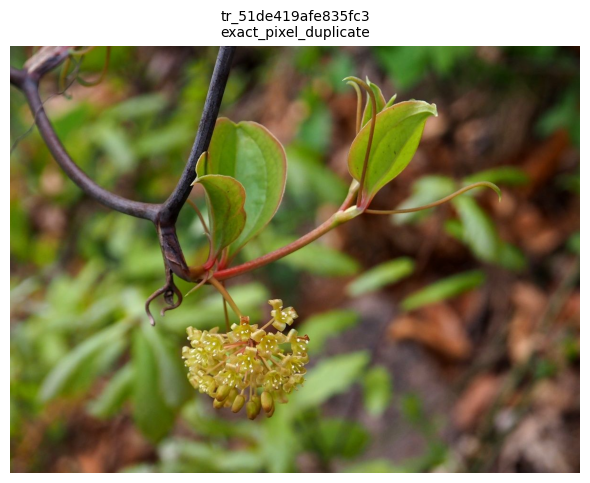

In [12]:
# Visualize any images excluded by the updated export and print their reasons.
import csv
import json

import matplotlib.pyplot as plt
from PIL import Image, ImageOps

excluded_path = prepared_dir / "manifests" / "excluded.csv"

with excluded_path.open(encoding="utf-8", newline="") as f:
    excluded = list(csv.DictReader(f))

audit_payload = json.loads(audit_path.read_text(encoding="utf-8"))
records = {row["sample_id"]: row for row in audit_payload["records"]}

if not excluded:
    print("No images were excluded.")
else:
    fig, axes = plt.subplots(
        1, len(excluded), figsize=(6 * len(excluded), 5), squeeze=False
    )

    for ax, row in zip(axes[0], excluded):
        sample_id = row["sample_id"]
        source_path = records[sample_id]["source_path"]

        print(f"{sample_id}: {row['reason']}")
        print(f"Original file: {source_path}\n")

        ax.set_title(f"{sample_id}\n{row['reason']}", fontsize=10)
        ax.axis("off")

        try:
            with Image.open(source_path) as image:
                ax.imshow(ImageOps.exif_transpose(image).convert("RGB"))
        except OSError as exc:
            ax.text(
                0.5, 0.5, f"Could not open image:\n{exc}",
                ha="center", va="center", wrap=True,
                transform=ax.transAxes,
            )

    plt.tight_layout()
    plt.show()

## 6.3 · Compare the known duplicate pair

Display the previously identified flower-image pair, `tr_51de419afe835fc3` and `tr_30fa478922d7a31b`, side by side. `np.array_equal()` checks whether their EXIF-corrected RGB pixels match exactly.

If it prints `True`, keeping one copy preserves the image content. This diagnostic does not change the export; final exclusions and reference IDs remain recorded in `excluded.csv`. Next, check the dataset totals and saved evaluation targets.

Excluded duplicate: /content/drive/MyDrive/AAI521/Final_project/PlantSR_dataset/train/img553.jpg
Kept image: /content/drive/MyDrive/AAI521/Final_project/PlantSR_dataset/train/img552.jpg


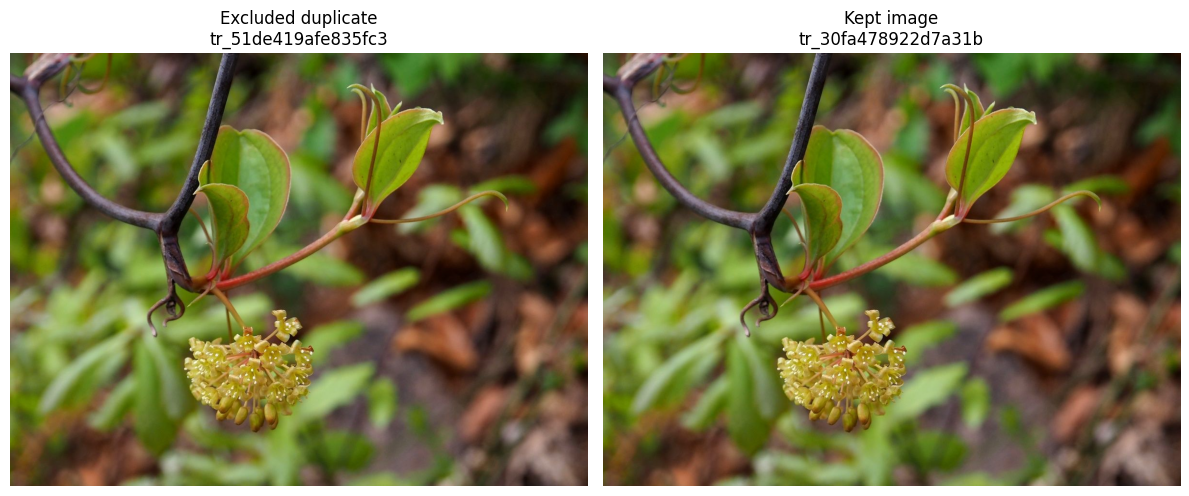

Identical RGB pixels: True


In [14]:
# two images are duplicated, only keep one
import json

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageOps

audit_payload = json.loads(audit_path.read_text(encoding="utf-8"))
records = {row["sample_id"]: row for row in audit_payload["records"]}

samples = [
    ("Excluded duplicate", "tr_51de419afe835fc3"),
    ("Kept image", "tr_30fa478922d7a31b"),
]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
pixels = []

for ax, (label, sample_id) in zip(axes, samples):
    source_path = records[sample_id]["source_path"]

    with Image.open(source_path) as image:
        rgb = ImageOps.exif_transpose(image).convert("RGB")
        array = np.array(rgb)

    pixels.append(array)
    ax.imshow(array)
    ax.set_title(f"{label}\n{sample_id}")
    ax.axis("off")
    print(f"{label}: {source_path}")

plt.tight_layout()
plt.show()

print("Identical RGB pixels:", np.array_equal(pixels[0], pixels[1]))

## 6.4 · Verify img271.jpg and its inclusion

Inspect the source file's actual format, mode, and alpha range. Your earlier result was PNG, RGBA, and `(255, 255)`, meaning every pixel is fully opaque despite the `.jpg` extension.

Then search the exported manifests and print the image's assigned split, sample ID, and saved RGB path. This verifies that the new export includes it; checking the alpha range alone would not detect an old cached exclusion. The split is read from the manifest rather than assumed.

In [13]:
# Inspect img271.jpg and verify its inclusion in the exported manifests.
from PIL import Image

path = TRAIN_DIR / "img271.jpg"

with Image.open(path) as img:
    alpha = img.convert("RGBA").getchannel("A")
    print("Actual format:", img.format)
    print("Image mode:", img.mode)
    print("Alpha min/max:", alpha.getextrema())

# Verify inclusion in the actual exported manifests, not only the alpha values.
matches = []
for split in ("train", "val", "test"):
    for row in read_csv(prepared_dir / "manifests" / f"{split}.csv"):
        if row["official_split"] == "official_train" and row["relative_path"] == "img271.jpg":
            matches.append((split, row))

if len(matches) != 1:
    raise RuntimeError(
        "Expected img271.jpg exactly once in the exported manifests. "
        "Check the new audit and manifests/excluded.csv before sharing."
    )

split, row = matches[0]
print(f"Included in {split}: {row['sample_id']}")
print(f"Prepared RGB image: {prepared_dir / row['hr_path']}")

Actual format: PNG
Image mode: RGBA
Alpha min/max: (255, 255)
Included in train: tr_c9d960dba6fe0aee
Prepared RGB image: /content/drive/MyDrive/AAI521/Final_project/PlantSR_prepared_opaque_v2_center256/prepared/images/train/tr_c9d960dba6fe0aee.png


Saved image: (1440, 824), mode=RGB


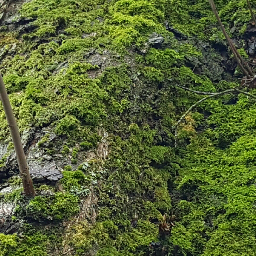

In [19]:
# inspect the 256 x 256 center crop
from IPython.display import display
from PIL import Image

path = prepared_dir / "images/train/tr_c9d960dba6fe0aee.png"

with Image.open(path) as img:
    print(f"Saved image: {img.size}, mode={img.mode}")
    crop = img.crop(center_crop_box(img.width, img.height, 256))
    display(crop)

## 7.1 · Check final counts and locate the shared dataset

Read the completed export's summary to confirm the final train/validation/test counts and exclusion reasons. The cell also displays one saved center crop from each evaluation split.



| Split | Image count |
|---|---:|
| train | 663 |
| val | 166 |
| test | 200 |

Excluded images 1
Exclusion reasons {'exact_pixel_duplicate': 1}
Split manifests: /content/drive/MyDrive/AAI521/Final_project/PlantSR_prepared_opaque_v2_center256/prepared/manifests
Summary report: /content/drive/MyDrive/AAI521/Final_project/PlantSR_prepared_opaque_v2_center256/prepared/summary.json
val example tr_00e349d3e0174f79, top-left corner (672, 472)


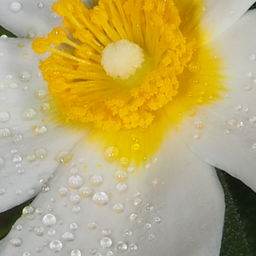

test example te_008927b393221bf9, top-left corner (672, 410)


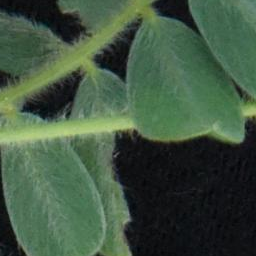

In [15]:
# Show final split counts, exclusion reasons, output paths, and example crops.
summary = json.loads(summary_path.read_text(encoding="utf-8"))
counts_table = ["| Split | Image count |", "|---|---:|"]
for split, count in summary["final_counts"].items():
    counts_table.append(f"| {split} | {count} |")
display(Markdown("\n".join(counts_table)))
print("Excluded images", summary["excluded_total"])
if summary["exclusion_counts"]:
    print("Exclusion reasons", summary["exclusion_counts"])
if summary["official_test_excluded"]:
    print("See summary.json for images excluded from the official test set.")
if summary["related_groups_within_test"]:
    print("See summary.json for groups of test images that share an original.")

print(f"Split manifests: {prepared_dir / 'manifests'}")
print(f"Summary report: {summary_path}")
for split in ("val", "test"):
    examples = read_csv(prepared_dir / "manifests" / f"{split}.csv")
    example = examples[0]
    print(
        f"{split} example {example['sample_id']}, "
        f"top-left corner ({example['crop_x']}, {example['crop_y']})"
    )
    display(DisplayImage(filename=str(prepared_dir / example["eval_crop_path"])))

## 7.2 · Preview 16 fixed evaluation crops

Select 16 saved crops from `test.csv` (or change `SPLIT` to `"val"`) and display their sample IDs and crop coordinates. The preview seed chooses which images to display; it does not change the saved crop positions or split assignments.

Use this quick grid to check crop dimensions, image content, and typical plant detail before viewing the complete galleries below. Some center crops can be dominated by background.

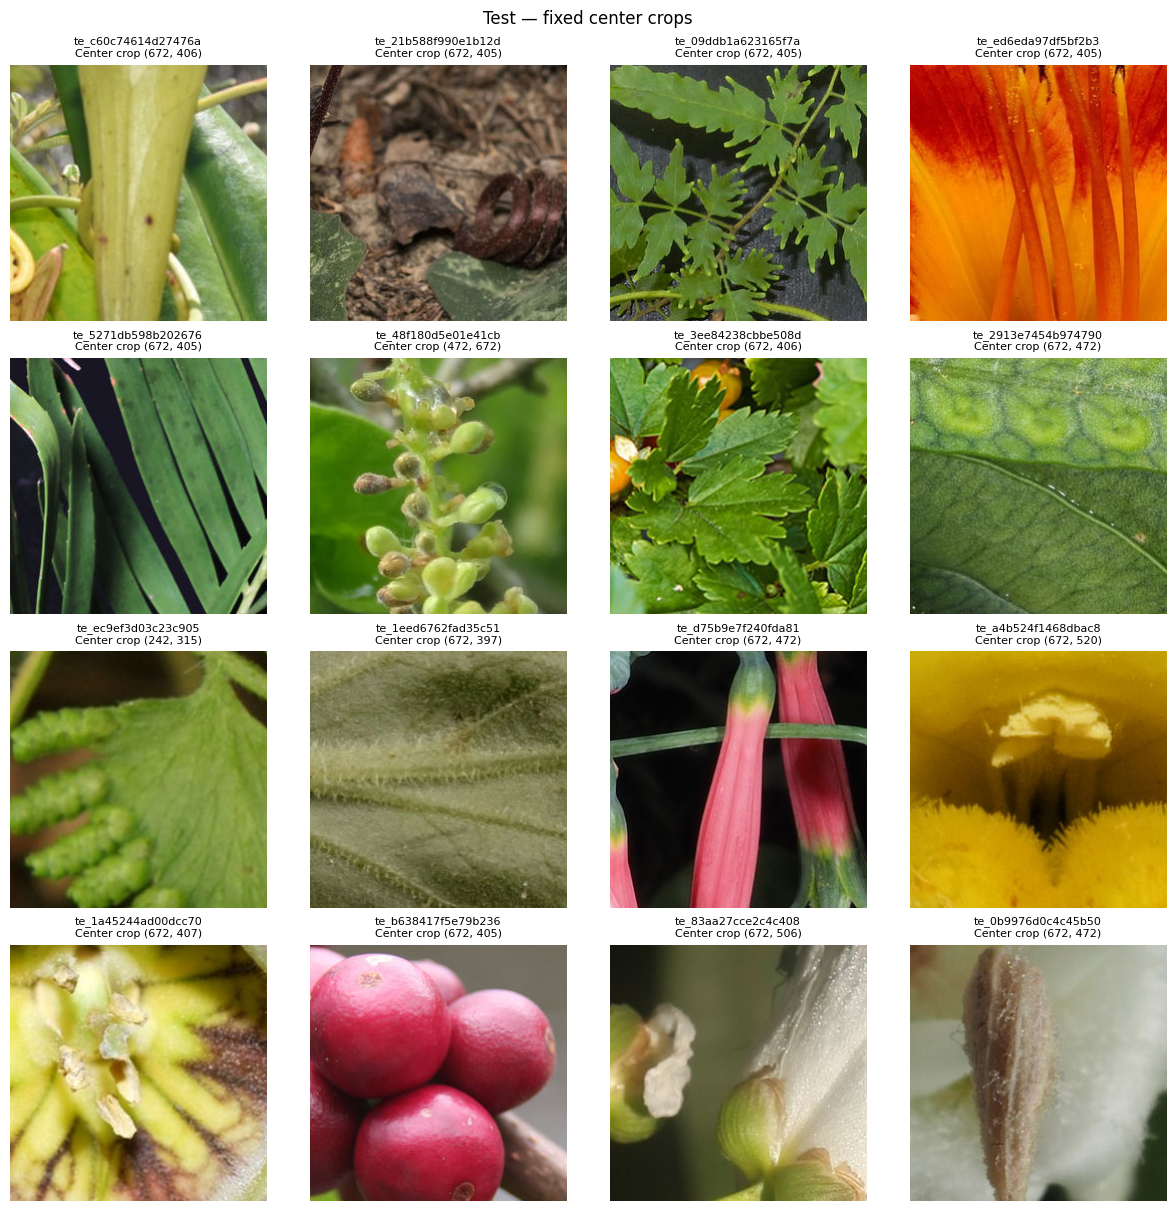

In [16]:
# Preview 16 saved center crops without changing the dataset.
import random
import matplotlib.pyplot as plt

SPLIT = "test"  # "val" or "test"
rows = read_csv(prepared_dir / "manifests" / f"{SPLIT}.csv")
samples = random.Random(42).sample(rows, min(16, len(rows)))
fig, axes = plt.subplots(4, 4, figsize=(12, 12), layout="constrained")
for axis in axes.flat:
    axis.axis("off")
for axis, row in zip(axes.flat, samples):
    with Image.open(prepared_dir / row["eval_crop_path"]) as crop:
        axis.imshow(crop.convert("RGB"))
    axis.set_title(
        f"{row['sample_id']}\nCenter crop ({row['crop_x']}, {row['crop_y']})",
        fontsize=8,
    )
fig.suptitle(f"{SPLIT.title()} — fixed center crops")
plt.show()


## 7.3 · Display all test center crops

Read every entry in `test.csv` and display its saved 256 × 256 crop in pages of 25 images. Page titles report the actual number of images and pages, and each tile shows the sample ID.

This is a visual check of the prepared targets, not a model evaluation. The cell only reads images and closes each figure after display. Keep the test set reserved for final evaluation once the dataset version is frozen.

In [17]:
# all the 256x256 cropped images in the test set
from math import ceil

import matplotlib.pyplot as plt
from PIL import Image

rows = read_csv(prepared_dir / "manifests" / "test.csv")
images_per_page = 25
total_pages = ceil(len(rows) / images_per_page)

for start in range(0, len(rows), images_per_page):
    page_rows = rows[start:start + images_per_page]
    page = start // images_per_page + 1

    fig, axes = plt.subplots(5, 5, figsize=(14, 14), layout="constrained")

    for ax in axes.flat:
        ax.axis("off")

    for ax, row in zip(axes.flat, page_rows):
        crop_path = prepared_dir / row["eval_crop_path"]
        with Image.open(crop_path) as crop:
            ax.imshow(crop.convert("RGB"))
        ax.set_title(row["sample_id"], fontsize=8)

    fig.suptitle(
        f"Test center crops | Page {page}/{total_pages} | "
        f"Images {start + 1}–{start + len(page_rows)} of {len(rows)}"
    )
    plt.show()
    plt.close(fig)

Output hidden; open in https://colab.research.google.com to view.

## 7.4 · Display all validation center crops

Repeat the full gallery for `val.csv`, with up to 25 saved crops per page. Use these same validation targets when comparing checkpoints during fine-tuning; generate task-specific degraded inputs reproducibly from them.

After checking the output, share the new `prepared/` folder and its manifests so all teammates use the same dataset version and fixed evaluation regions.

In [18]:
# all the 256x256 cropped images in the validation set
from math import ceil

import matplotlib.pyplot as plt
from PIL import Image

rows = read_csv(prepared_dir / "manifests" / "val.csv")
images_per_page = 25
total_pages = ceil(len(rows) / images_per_page)

for start in range(0, len(rows), images_per_page):
    page_rows = rows[start:start + images_per_page]
    page = start // images_per_page + 1

    fig, axes = plt.subplots(5, 5, figsize=(14, 14), layout="constrained")

    for ax in axes.flat:
        ax.axis("off")

    for ax, row in zip(axes.flat, page_rows):
        crop_path = prepared_dir / row["eval_crop_path"]
        with Image.open(crop_path) as crop:
            ax.imshow(crop.convert("RGB"))
        ax.set_title(row["sample_id"], fontsize=8)

    fig.suptitle(
        f"Validation center crops | Page {page}/{total_pages} | "
        f"Images {start + 1}–{start + len(page_rows)} of {len(rows)}"
    )
    plt.show()
    plt.close(fig)

Output hidden; open in https://colab.research.google.com to view.

## 7.4 · Package the prepared dataset for sharing

Create a ZIP archive of the entire `prepared/` folder, including the images, crops, manifests, and export summary. Share the ZIP with my teammates. The original files remain in place.

After extracting the ZIP, use `prepared/` as the base directory for the relative paths in the CSV manifests. When generating degraded inputs, preserve each source image’s `sample_id` and split assignment.

In [20]:
from pathlib import Path
from zipfile import ZIP_STORED, ZipFile

prepared_dir = Path(prepared_dir)
if not (prepared_dir / "summary.json").is_file():
    raise FileNotFoundError("Run the dataset export before creating the ZIP.")

zip_path = prepared_dir.parent / "PlantSR_prepared_for_team.zip"

# Mode "x" creates a new ZIP and protects any existing ZIP from being overwritten.
# The images are already PNGs, so package them without extra compression.
file_count = 0
with ZipFile(zip_path, mode="x", compression=ZIP_STORED) as archive:
    for path in sorted(prepared_dir.rglob("*")):
        if path.is_file():
            archive.write(path, arcname=path.relative_to(prepared_dir.parent))
            file_count += 1

print(f"Packed {file_count:,} files ({zip_path.stat().st_size / 1024**2:,.1f} MB).")
print(f"Share this ZIP: {zip_path}")

Packed 1,400 files (1,712.6 MB).
Share this ZIP: /content/drive/MyDrive/AAI521/Final_project/PlantSR_prepared_opaque_v2_center256/PlantSR_prepared_for_team.zip
